In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pandas_datareader import data as web
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
%pip install pandas-datareader


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /Users/ece/uw-ml/wne-uw-ml1-qf-labs-materials/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
# Task 1: Download daily US Treasury yields from FRED

start_date = "2010-01-01"
end_date = "2026-10-23"

treasury_series = {
    "3M": "DGS3MO",
    "6M": "DGS6MO",
    "1Y": "DGS1",
    "2Y": "DGS2",
    "3Y": "DGS3",
    "5Y": "DGS5",
    "7Y": "DGS7",
    "10Y": "DGS10",
    "20Y": "DGS20",
    "30Y": "DGS30"
}

yields = web.DataReader(
    list(treasury_series.values()),
    "fred",
    start_date,
    end_date
)

yields.columns = list(treasury_series.keys())

print("Dataset shape:", yields.shape)
print("Date range:", yields.index.min(), "to", yields.index.max())

display(yields.head())

Dataset shape: (4384, 10)
Date range: 2010-01-01 00:00:00 to 2026-10-21 00:00:00


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
DATE,,,,,,,,,,
2010-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-04,0.08,0.18,0.45,1.09,1.66,2.65,3.36,3.85,4.60,4.65
2010-01-05,0.07,0.17,0.41,1.01,1.57,2.56,3.28,3.77,4.54,4.59
2010-01-06,0.06,0.15,0.40,1.01,1.60,2.60,3.33,3.85,4.63,4.70
2010-01-07,0.05,0.16,0.40,1.03,1.62,2.62,3.33,3.85,4.62,4.69


In [17]:
# Check missing values in Treasury yield data

print("Missing values by maturity:")
print(yields.isna().sum())

print("\nRows before cleaning:", len(yields))

yields_clean = yields.dropna()

print("Rows after cleaning:", len(yields_clean))
print("Clean date range:",
      yields_clean.index.min(),
      "to",
      yields_clean.index.max())

display(yields_clean.head())

Missing values by maturity:
3M     181
6M     181
1Y     181
2Y     181
3Y     181
5Y     181
7Y     181
10Y    181
20Y    181
30Y    181
dtype: int64

Rows before cleaning: 4384
Rows after cleaning: 4203
Clean date range: 2010-01-04 00:00:00 to 2026-10-21 00:00:00


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
DATE,,,,,,,,,,
2010-01-04,0.08,0.18,0.45,1.09,1.66,2.65,3.36,3.85,4.60,4.65
2010-01-05,0.07,0.17,0.41,1.01,1.57,2.56,3.28,3.77,4.54,4.59
2010-01-06,0.06,0.15,0.40,1.01,1.60,2.60,3.33,3.85,4.63,4.70
2010-01-07,0.05,0.16,0.40,1.03,1.62,2.62,3.33,3.85,4.62,4.69
2010-01-08,0.05,0.15,0.37,0.96,1.56,2.57,3.31,3.83,4.61,4.70


In [18]:
# Calculate daily changes in Treasury yields (basis points)

yield_changes = yields_clean.diff().dropna() * 100

print("Daily yield changes shape:", yield_changes.shape)
print("Date range:", yield_changes.index.min(),
      "to", yield_changes.index.max())

display(yield_changes.head())

Daily yield changes shape: (4202, 10)
Date range: 2010-01-05 00:00:00 to 2026-10-21 00:00:00


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
DATE,,,,,,,,,,
2010-01-05,-1.0,-1.0,-4.0,-8.0,-9.0,-9.0,-8.0,-8.0,-6.0,-6.0
2010-01-06,-1.0,-2.0,-1.0,0.0,3.0,4.0,5.0,8.0,9.0,11.0
2010-01-07,-1.0,1.0,0.0,2.0,2.0,2.0,0.0,0.0,-1.0,-1.0
2010-01-08,0.0,-1.0,-3.0,-7.0,-6.0,-5.0,-2.0,-2.0,-1.0,1.0
2010-01-11,-1.0,-2.0,-2.0,-1.0,-1.0,1.0,1.0,2.0,3.0,4.0


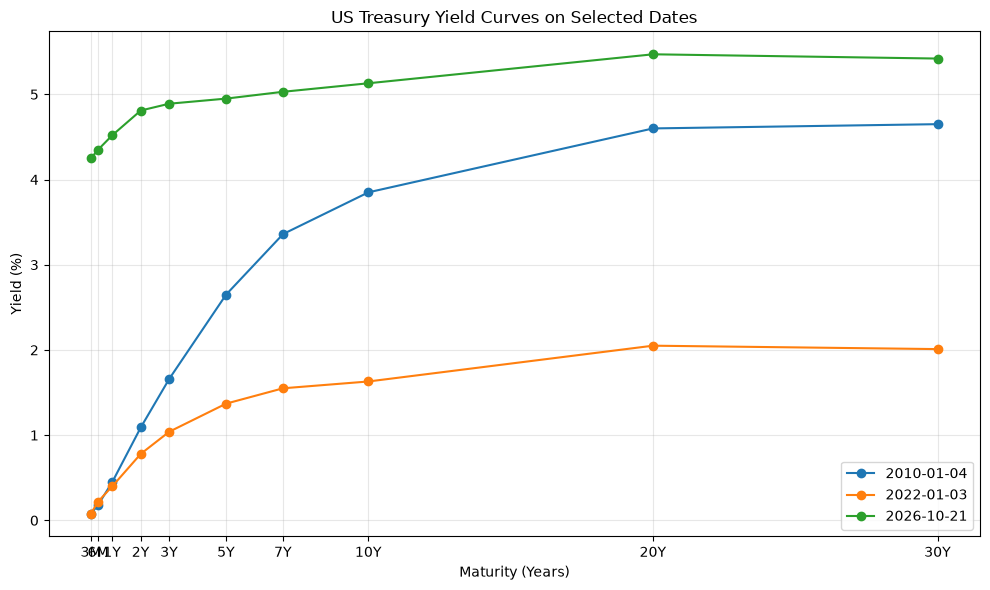

In [19]:
# Plot US Treasury yield curves on selected dates

maturities = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]

selected_dates = [
    "2010-01-04",
    "2022-01-03",
    yields_clean.index[-1]
]

plt.figure(figsize=(10, 6))

for date in selected_dates:
    curve = yields_clean.loc[date]
    plt.plot(
        maturities,
        curve.values,
        marker="o",
        label=pd.Timestamp(date).strftime("%Y-%m-%d")
    )

plt.title("US Treasury Yield Curves on Selected Dates")
plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.xticks(maturities, yields_clean.columns)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Principal Component Analysis of daily Treasury yield changes

pca = PCA(n_components=10)
pca.fit(yield_changes)

explained_variance = pd.DataFrame({
    "Principal Component": [f"PC{i}" for i in range(1, 11)],
    "Explained Variance (%)": pca.explained_variance_ratio_ * 100
})

explained_variance["Cumulative Variance (%)"] = (
    explained_variance["Explained Variance (%)"].cumsum()
)

display(explained_variance.round(2))

print(
    "Variance explained by the first 3 PCs:",
    round(explained_variance["Explained Variance (%)"].iloc[:3].sum(), 2),
    "%"
)

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,80.11,80.11
1,PC2,11.70,91.81
2,PC3,3.94,95.74
3,PC4,1.64,97.39
4,PC5,0.91,98.30
5,PC6,0.67,98.97
6,PC7,0.44,99.41
7,PC8,0.24,99.65
8,PC9,0.20,99.85
9,PC10,0.15,100.00


Variance explained by the first 3 PCs: 95.74 %


PCA Loadings:


,PC1,PC2,PC3
3M,0.0543,0.1921,0.6403
6M,0.0943,0.2805,0.4910
1Y,0.1707,0.4203,0.2538
2Y,0.2947,0.4447,-0.1514
3Y,0.3451,0.3331,-0.2506
5Y,0.4003,0.1171,-0.2473
7Y,0.4173,-0.0578,-0.1533
10Y,0.3985,-0.2024,-0.0003
20Y,0.3698,-0.3894,0.2032
30Y,0.3509,-0.4352,0.2698


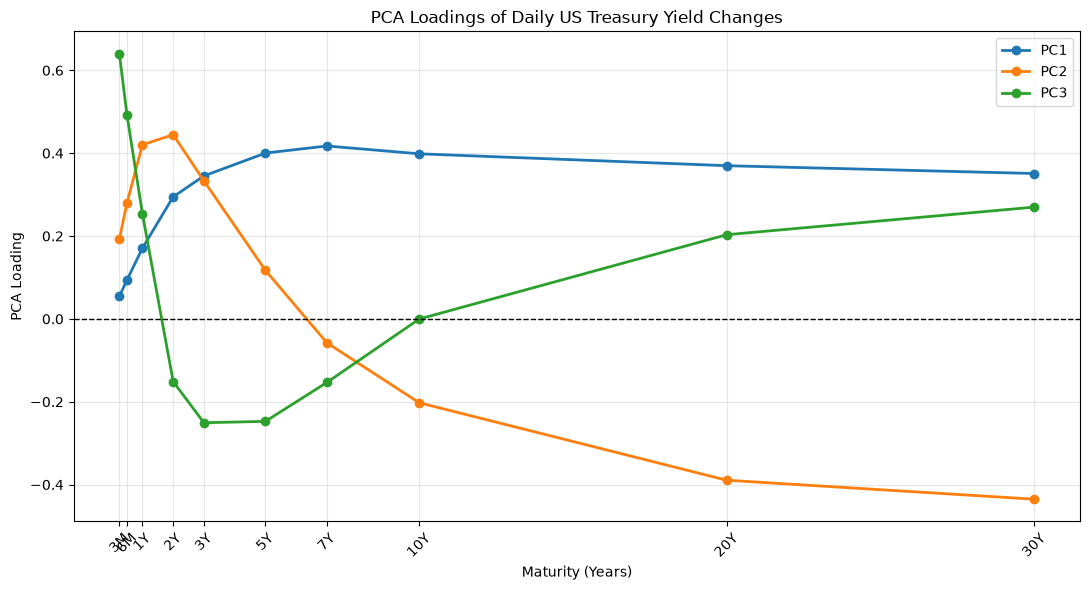

In [21]:
# PCA loadings for the first three components

loadings = pd.DataFrame(
    pca.components_[:3].T,
    index=yield_changes.columns,
    columns=["PC1", "PC2", "PC3"]
)

print("PCA Loadings:")
display(loadings.round(4))

maturities = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]

plt.figure(figsize=(11, 6))

for pc in ["PC1", "PC2", "PC3"]:
    plt.plot(
        maturities,
        loadings[pc],
        marker="o",
        linewidth=2,
        label=pc
    )

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("PCA Loadings of Daily US Treasury Yield Changes")
plt.xlabel("Maturity (Years)")
plt.ylabel("PCA Loading")
plt.xticks(maturities, loadings.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

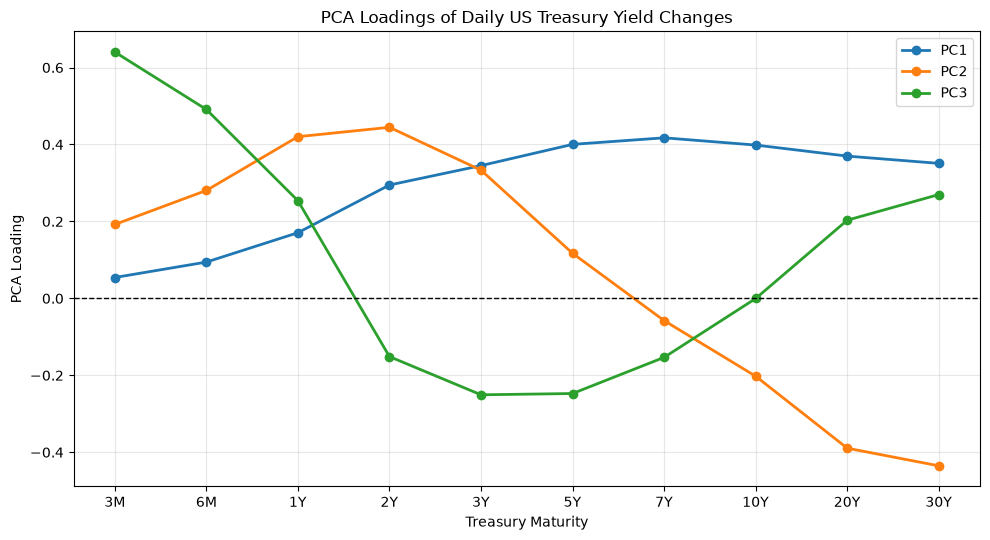

In [22]:
# Publication-ready PCA loadings plot

maturity_labels = list(loadings.index)
x_positions = np.arange(len(maturity_labels))

plt.figure(figsize=(10, 5.5))

for pc in ["PC1", "PC2", "PC3"]:
    plt.plot(
        x_positions,
        loadings[pc].values,
        marker="o",
        linewidth=2,
        label=pc
    )

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("PCA Loadings of Daily US Treasury Yield Changes")
plt.xlabel("Treasury Maturity")
plt.ylabel("PCA Loading")
plt.xticks(x_positions, maturity_labels)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

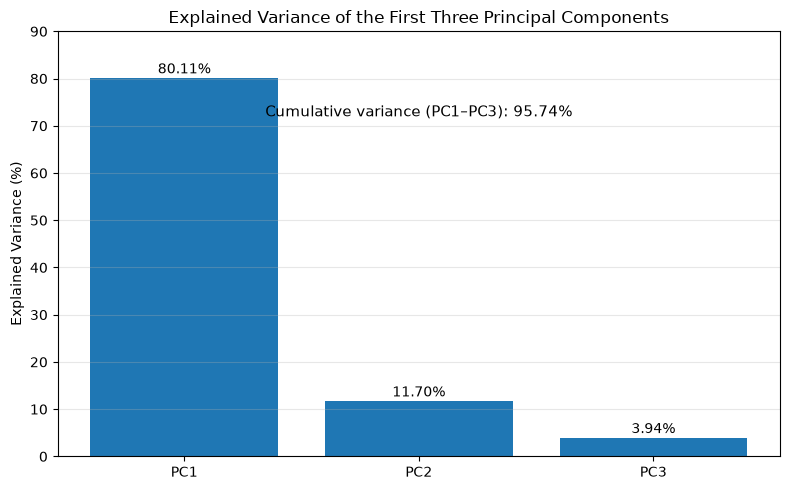

In [23]:
# Explained variance of the first three principal components

components = ["PC1", "PC2", "PC3"]
variance_values = pca.explained_variance_ratio_[:3] * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(components, variance_values)

for bar, value in zip(bars, variance_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.title("Explained Variance of the First Three Principal Components")
plt.ylabel("Explained Variance (%)")
plt.ylim(0, 90)
plt.grid(axis="y", alpha=0.3)

plt.text(
    1, 72,
    f"Cumulative variance (PC1–PC3): {variance_values.sum():.2f}%",
    ha="center",
    fontsize=11
)

plt.tight_layout()
plt.show()

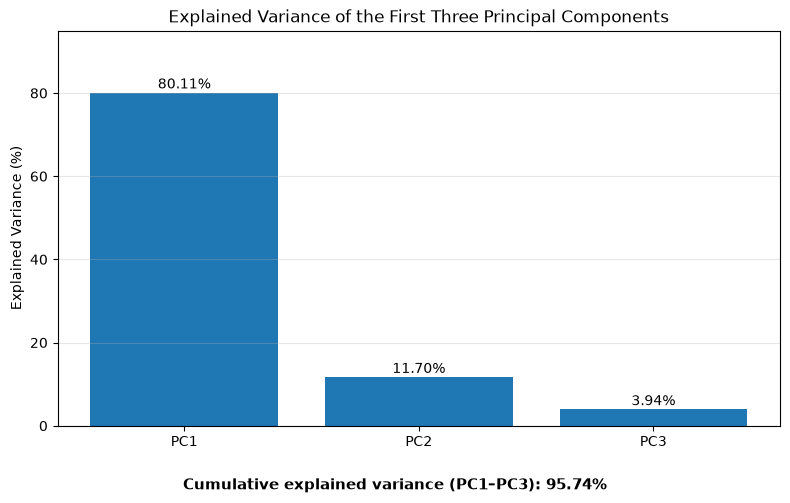

In [24]:
# Final explained variance plot

components = ["PC1", "PC2", "PC3"]
variance_values = pca.explained_variance_ratio_[:3] * 100

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(components, variance_values)

for bar, value in zip(bars, variance_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

ax.set_title("Explained Variance of the First Three Principal Components")
ax.set_ylabel("Explained Variance (%)")
ax.set_ylim(0, 95)
ax.grid(axis="y", alpha=0.3)

total_variance = variance_values.sum()

fig.text(
    0.5, 0.01,
    f"Cumulative explained variance (PC1–PC3): {total_variance:.2f}%",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Results Interpretation

We analysed daily changes in US Treasury yields across 10 maturities, from 3 months to 30 years, using data from January 2010 to October 2026. After removing missing observations and calculating daily yield changes in basis points, the PCA was performed on 4,202 observations without standardising the maturity series.

The first three principal components explain **95.74% of the total variance**, consistent with the approximately 95% described in the lecture.

- **PC1 – Level (80.11%):** All maturities have positive loadings, indicating a common movement in yields. The loadings are larger at medium and longer maturities, so the movement is not perfectly parallel.
- **PC2 – Slope (11.70%):** Short-term and long-term yields have opposite-signed loadings, representing changes in the steepness of the yield curve.
- **PC3 – Curvature (3.94%):** Short and long maturities have positive loadings, while intermediate maturities have negative loadings, representing movements of the belly relative to the wings.

Overall, the results suggest that three common factors capture most daily movements in the US Treasury yield curve.